In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

import matplotlib.colors as mcolors
from matplotlib.collections import EllipseCollection
import matplotlib.gridspec as gridspec

import MDAnalysis as mda
from MDAnalysis.analysis.distances import capped_distance
import MDAnalysis.transformations as trans

from plot_local_water_density import *

/Users/nate_schwindt/anaconda3/envs/mda/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/Users/nate_schwindt/anaconda3/envs/mda/lib/python3.10/site-packages/Bio/Application/__init__.py:40: BiopythonDeprecationWarning: The Bio.Application modules and modules relying on it have been deprecated.

Due to the on going maintenance burden of keeping command line application
wrappers up to date, we have decided to deprecate and eventually remove these
modules.

We instead now recommend building your command line and invoking it directly
with the subprocess module.
  warnings.warn(


In [2]:
path = './'
tpr = path + 'prod.tpr'
xtc = path + 'prod_centered.xtc'
selection = 'cl'
idx = 3
distance_cutoff = 8.0
visualization_cutoff = 5.0
z_threshold = 2.25

print(f'Loading {tpr} with trajectory {xtc}')
u = mda.Universe(tpr, xtc)
ag = get_atom_group(selection, u)
my_atom = ag[idx]

# center on my_atom
workflow = [
    trans.center_in_box(mda.AtomGroup([my_atom])),
    trans.wrap(u.atoms)
]
u.trajectory.add_transformations(*workflow)

Loading ./prod.tpr with trajectory ./prod_centered.xtc


In [3]:
# get the coordinates and distances for all frames
df = pd.DataFrame(columns=['x', 'y', 'z', 'distance_to_atom', 'frame'])
df_cl = pd.DataFrame(columns=['x', 'y', 'z', 'frame'])
for ts in u.trajectory:

    pairs, distances = capped_distance(my_atom.position, u.atoms, max_cutoff=distance_cutoff, box=u.dimensions)
    my_neighbors = u.atoms[pairs[:,1]]
    tmp = pd.DataFrame(my_neighbors.positions, columns=['x', 'y', 'z'])
    tmp['element'] = my_neighbors.elements
    tmp['type'] = my_neighbors.types
    tmp['distance_to_atom'] = distances[(pairs[:,0] == 0)]
    tmp['frame'] = u.trajectory.frame
    tmp['my_atom_index'] = my_neighbors.indices
    tmp['bonded_indices'] = [atom.bonded_atoms.indices for atom in my_neighbors]
    df = pd.concat([df, tmp])

# transform coordinates to plane defined by 3 closest atoms to my_atom in each frame
df = add_plane_aligned_coords(df)
df['vdw_radius'] = df['element'].map(vdw_radii)
df

/var/folders/c7/911byk5d5jl0vp7m92bxn01w0000gn/T/ipykernel_92784/367839465.py:15: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df = pd.concat([df, tmp])


,x,y,z,distance_to_atom,frame,element,type,my_atom_index,bonded_indices,x_plane,y_plane,z_plane,plane_anchor,vdw_radius
0,20.247650,29.352348,66.711349,7.046628,0,O,o,57.0,[224],0.381809,6.727221,2.062444e+00,False,1.52
1,24.982349,27.592346,67.331345,3.115857,0,C,c,63.0,"[76, 80, 81]",0.729430,2.800143,-1.155722e+00,False,1.70
2,24.822350,31.092346,70.961349,7.918488,0,N,n,74.0,"[62, 186, 192]",-0.051520,6.580938,-4.403528e+00,False,1.55
3,26.062349,27.352348,67.811348,3.173103,0,O,o,76.0,[63],0.862267,2.153552,-2.165016e+00,False,1.52
4,24.812349,25.132347,66.651352,2.654263,0,C,ca,77.0,"[80, 6466, 6643]",2.363681,1.207530,1.103026e-07,True,1.70
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
446414,25.208296,22.588299,59.423553,6.837050,2000,H,HW,35552.0,[35550],1.392898,2.884078,-6.040462e+00,False,1.20
446415,23.038296,29.738297,65.713547,4.784705,2000,O,OW,35661.0,"[35662, 35663]",-1.745829,-4.437774,-3.894203e-01,False,1.52
446416,22.268295,30.318298,65.503555,5.710011,2000,H,HW,35662.0,[35661],-2.100060,-5.243783,-8.346925e-01,False,1.20
446417,23.128296,29.068298,65.003555,4.210999,2000,H,HW,35663.0,[35661],-1.464195,-3.798458,-1.077202e+00,False,1.20


In [4]:
frame0 = df.query(f'frame == 0 and type not in ["HW", "OW"] and distance_to_atom <= {visualization_cutoff}').copy()
frame0

,x,y,z,distance_to_atom,frame,element,type,my_atom_index,bonded_indices,x_plane,y_plane,z_plane,plane_anchor,vdw_radius
1,24.982349,27.592346,67.331345,3.115857,0,C,c,63.0,"[76, 80, 81]",0.729430,2.800143e+00,-1.155722e+00,False,1.70
3,26.062349,27.352348,67.811348,3.173103,0,O,o,76.0,[63],0.862267,2.153552e+00,-2.165016e+00,False,1.52
4,24.812349,25.132347,66.651352,2.654263,0,C,ca,77.0,"[80, 6466, 6643]",2.363681,1.207530e+00,1.103026e-07,True,1.70
6,22.372349,28.082348,66.581352,4.668801,0,H,ha,79.0,[78],0.699486,4.503032e+00,1.015445e+00,False,1.20
7,24.322350,26.462349,66.851349,2.853155,0,N,n,80.0,"[63, 77, 230]",1.559779,2.386263e+00,-1.154753e-01,False,1.55
8,23.952349,28.372345,68.051346,4.500251,0,C,ca,81.0,"[63, 78, 235]",0.797362,4.277651e+00,-1.148117e+00,False,1.70
9,26.322350,26.322350,64.821350,0.000000,0,Cl,cl,82.0,[6466],0.000000,0.000000e+00,0.000000e+00,True,1.75
19,23.352348,26.572350,66.601349,3.471571,0,H,hn,230.0,[80],1.621187,2.991757e+00,6.877109e-01,False,1.20
23,26.952351,23.502346,64.621353,2.896432,0,H,ha,6447.0,[6452],1.943738,-2.116602e+00,3.622145e-01,False,1.20
24,26.312349,23.672348,65.491348,2.733405,0,C,ca,6452.0,"[6447, 6457, 6466]",2.461795,-1.179425e+00,1.415129e-01,False,1.70


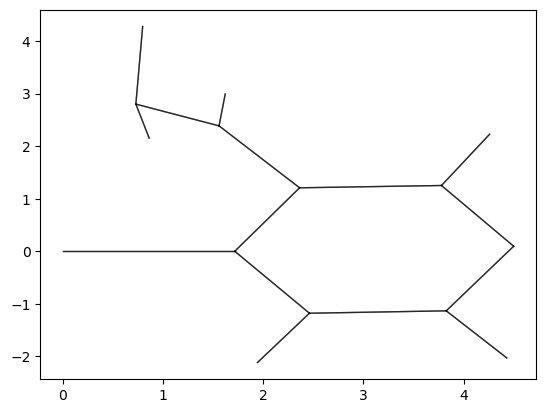

In [13]:
x = frame0['x_plane'].to_numpy()
y = frame0['y_plane'].to_numpy()

# Create a mapping from atom indices to position indices
idx_to_pos = {idx: i for i, idx in enumerate(frame0['my_atom_index'])}

# Draw lines between bonded atoms
for atom_idx, bonded_idx_list in zip(frame0['my_atom_index'],  frame0['bonded_indices']):
    for bonded_idx in bonded_idx_list:
        if bonded_idx in idx_to_pos:
            pos_i = idx_to_pos[atom_idx]
            pos_j = idx_to_pos[bonded_idx]
            plt.plot([x[pos_i], x[pos_j]], [y[pos_i], y[pos_j]], 'k-', linewidth=1.0, alpha=0.6, zorder=1)